# The dependence band and the worst-case VaR bounds

**Question:** Is the simple sum the most capital Banco Andino's four risks could ever need, and between which two numbers must
every diversified answer lie whatever the dependence between the risks?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the simple sum, the copulas and the committed band)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- explain why the comonotonic VaR, the VaR of perfectly dependent risks, is not the worst case, with a published example whose
  answer is known;
- follow the rearrangement algorithm on a matrix small enough to print and say what it does to the row sums;
- run the engine's band on the four marginals of Banco Andino and read each row, headline or information, with its
  dependence on the correlation matrix;
- check that every row lies inside the bracket the best and worst VaR define, and see the check turn red when a row is pushed
  out;
- read what a correlation stress moves in the band and what it cannot move.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the reader of the committed documents (three folders below the repository root)
import importlib.metadata as md
import json
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.aggregation import band as rv_band
from riskvalidation.aggregation import bounds
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the same case as notebooks 01 and 02, **C18** (Banco Andino).

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginals, matrix, committed band), `data/derived/C18/t-copula-baseline.json` (`outputs.correlation_stress`: the same band with the market-credit correlation raised to 0.8) and `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`, the marginals' quantile functions).
- **The marginals are rebuilt from the committed quantile grids in the simulated steps.** As in notebook 02, the models document holds each marginal's quantile function on a named grid and not the simulated losses, so step 3 rebuilds the four marginals from it and runs the band on them with the pipeline's settings; the committed band is expected back to within 0.01 percent. Steps 1 and 2 use a published example with closed-form marginals instead, so that the algorithm can be checked against a formula.

In [2]:
# The baseline and stressed aggregation blocks and the committed quantile grids of the four marginals
agg = read_json("C18/baseline.json")["outputs"]["aggregation"]
stress = read_json("C18/t-copula-baseline.json")["outputs"]["correlation_stress"]
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
marginals = agg["marginals"]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
stressed = {(r["method"], r["nu"]): r for r in stress["aggregation"]["band"]}
LIGHT = {"green": "green", "amber": "amber", "red": "red"}
NAMES = {"lower-bound": "lower bound", "simple-sum": "simple sum",
         "variance-covariance": "variance-covariance", "gaussian-copula": "Gaussian copula",
         "t-copula": "t copula", "worst-case": "worst case"}

## Method

### Step 1: the comonotonic VaR is not the worst case

When the dependence between the risks is unknown, a natural but wrong upper bound is the **comonotonic VaR**, the VaR of the sum when the risks move together perfectly: $\mathrm{VaR}_q(L_1 + \dots + L_d) = \sum_k F_k^{-1}(q)$. It is the simple sum of the VaRs, exact for perfect dependence. But **VaR is not subadditive**, so some other dependence can give a larger VaR of the sum (Embrechts, McNeil and Straumann 2002; Embrechts, Puccetti and Rueschendorf 2013). The engine computes the exact best and worst VaR over all dependence structures, given only the marginals.

The published example of Embrechts, Puccetti and Rueschendorf (2013, Table 4) uses Pareto(2) marginals, $F(x) = 1 - (1+x)^{-2}$, so $F^{-1}(q) = (1-q)^{-1/2} - 1$ in closed form, with $d = 8$ risks.

The next cell builds the eight Pareto(2) quantile functions as the Lomax distribution of scipy, runs `comonotonic_var` and
`worst_var_bounds` with the pipeline's settings ($N = 10^5$ cells, $\epsilon = 10^{-3}$), and prints the three VaRs.

In [3]:
# Eight Pareto(2) marginals of the published example: the comonotonic VaR, then the sharp bounds
D, Q = 8, 0.99
pareto = [partial(stats.lomax.ppf, c=2)] * D
como = bounds.comonotonic_var(pareto, Q)
sharp = bounds.worst_var_bounds(pareto, Q, 100_000, 1e-3, seed=0)
print("comonotonic VaR", round(como, 4), "closed form", round(D * ((1 - Q) ** -0.5 - 1), 4))
print("best VaR range", np.round(sharp.lower_range, 3))
print("worst VaR range", np.round(sharp.upper_range, 3))
print("sweeps of the four runs", sharp.sweeps, "converged", sharp.converged)
print("worst VaR over the comonotonic VaR", round(sharp.upper_range[1] / como, 3))

comonotonic VaR 72.0 closed form 72.0
best VaR range [8.995 9.   ]
worst VaR range [141.663 141.669]
sweeps of the four runs (4, 4, 5, 5) converged True
worst VaR over the comonotonic VaR 1.968


The comonotonic VaR is 72.0, which is what the closed form gives for eight Pareto(2) risks at 99 percent, and the worst VaR
is 141.66 to 141.67, 1.968 times larger. The best VaR, 9.00, is far below. The next cell repeats the run for two to eight
risks to show how the three numbers grow with the number of risks.

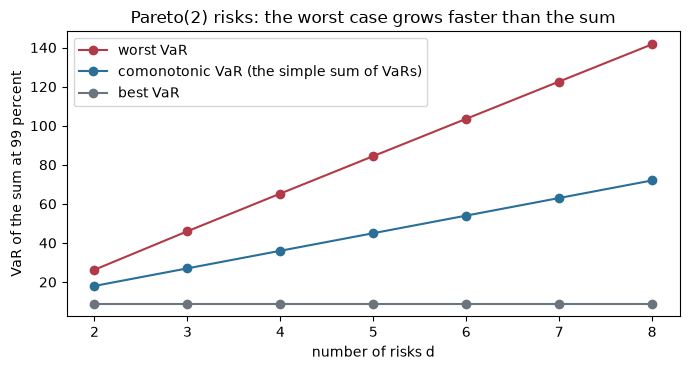

In [4]:
# The comonotonic, best and worst VaR of d Pareto(2) risks as d grows from 2 to 8
sizes = list(range(2, 9))
runs = [bounds.worst_var_bounds([pareto[0]] * d, Q, 100_000, 1e-3, seed=0) for d in sizes]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(sizes, [r.upper_range[1] for r in runs], marker="o", color="#b23a48", label="worst VaR")
ax.plot(sizes, [bounds.comonotonic_var([pareto[0]] * d, Q) for d in sizes], marker="o", color="#2a6f97",
        label="comonotonic VaR (the simple sum of VaRs)")
ax.plot(sizes, [r.lower_range[0] for r in runs], marker="o", color="#6c757d", label="best VaR")
ax.set_xlabel("number of risks d")
ax.set_ylabel("VaR of the sum at 99 percent")
ax.set_title("Pareto(2) risks: the worst case grows faster than the sum")
ax.legend()
fig.tight_layout()
plt.show()

With two risks the worst VaR is already 26.3 against a comonotonic 18.0, and the gap widens with every risk added: with eight
the worst case is about twice the sum of the VaRs. The best VaR stays near 9 whatever the number of risks, because the best
arrangement lets the risks cancel almost completely in the tail. The three lines are the whole width of what dependence can
do to the VaR of a sum of heavy-tailed risks, and the simple sum is the middle one, not the top. The figure is a closed-form
published example and not Banco Andino, which comes at step 3.

### Step 2: how the rearrangement algorithm works

The worst VaR is the largest value that the **smallest** row sum can take. Take the upper $1 - q$ of each marginal, cut it into $N$ cells, and put the cell quantiles in a matrix $X$ of $N$ rows and $d$ columns. Any dependence in the tail is a permutation of each column. The **rearrangement algorithm** (Embrechts, Puccetti and Rueschendorf 2013, section 2.2) looks for the permutation that makes the row sums as equal as possible: it permutes the columns at random, then, one column at a time, reorders it **oppositely** to the sum of the others (the largest value next to the smallest rest), and repeats until the smallest row sum changes by less than $\epsilon$. Making every row sum equal is the "joint mixability" that gives the worst case: no row is left with a small total.

The next cell takes three Pareto(2) risks and ten cells over the top one percent, and calls `rearrangement_algorithm`. The
figure shows the row sums of the comonotonic matrix beside those of the rearranged one.

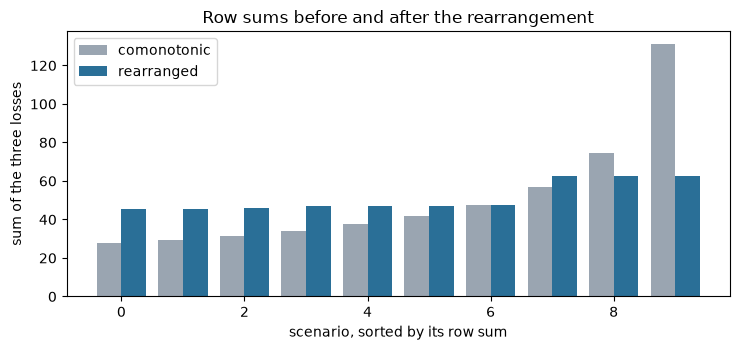

smallest row sum, comonotonic and rearranged 27.78 45.39
sweeps 4 converged True


In [5]:
# A 10 x 3 matrix of cell quantiles: the comonotonic row sums and the rearranged ones
cells = 10
midpoints = Q + (1 - Q) * (np.arange(cells) + 0.5) / cells
matrix = np.column_stack([pareto[0](midpoints)] * 3)
rearranged, value, sweeps, converged = bounds.rearrangement_algorithm(matrix, "max-min-row-sum", 1e-3, 1000, 0)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
scenario = np.arange(cells)
ax.bar(scenario - 0.2, np.sort(matrix.sum(axis=1)), width=0.4, color="#9aa5b1", label="comonotonic")
ax.bar(scenario + 0.2, np.sort(rearranged.sum(axis=1)), width=0.4, color="#2a6f97", label="rearranged")
ax.set_xlabel("scenario, sorted by its row sum")
ax.set_ylabel("sum of the three losses")
ax.set_title("Row sums before and after the rearrangement")
ax.legend()
fig.tight_layout()
plt.show()
print("smallest row sum, comonotonic and rearranged", round(matrix.sum(axis=1).min(), 2), round(value, 2))
print("sweeps", sweeps, "converged", converged)

The rearrangement only moves values inside each column, so the three marginals are untouched, yet the smallest row sum rises
from 27.78 to 45.39 and the sums bunch into a narrow range of 45 to 63, against 28 to 131 before. That is the mechanism by
which a dependence structure can ask for far more capital than perfect dependence: it spreads the extreme losses across
scenarios so that every scenario is bad, where the comonotonic arrangement piles them into one scenario and leaves the rest
mild. The algorithm converged in four sweeps; a VaR of the sum is the smallest of these sums at the worst arrangement.

### Step 3: the marginals of Banco Andino

For the case's four marginals the models document holds the quantile functions on the named grid of notebook 02 (1,961
probabilities, linear in the probability between points and clamped at the ends). The next cell rebuilds them, reads a
sample of $10^6$ Hazen positions from each, draws the loss quantile of each against the probability level and prints the
comonotonic VaR of the four, which less the sum of the expected losses is the simple sum.

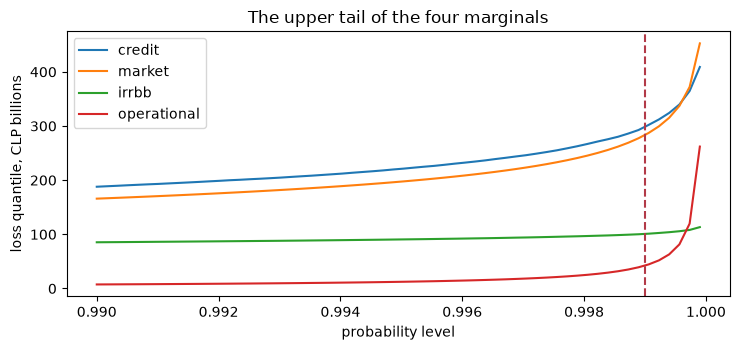

comonotonic VaR of the four, CLP millions 724858.9
sum of the expected losses 66728.7
comonotonic VaR less the expected losses 658130.2


In [6]:
# Rebuild the four marginals from the committed grids and read the comonotonic VaR of the four
LEVEL = 0.999
probs = np.array(grid["probabilities"])
ppfs = [partial(np.interp, xp=probs, fp=np.array(q["quantiles"])) for q in grid["marginals"]]
ec = np.array([m["ec_clp_m"] for m in marginals])
el = np.array([m["el_clp_m"] for m in marginals])
levels = np.linspace(0.99, 0.9999, 60)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for m, ppf in zip(marginals, ppfs):
    ax.plot(levels, ppf(levels) / 1e3, label=m["risk"])
ax.axvline(LEVEL, color="#b23a48", linestyle="--")
ax.set_xlabel("probability level")
ax.set_ylabel("loss quantile, CLP billions")
ax.set_title("The upper tail of the four marginals")
ax.legend()
fig.tight_layout()
plt.show()
como_four = bounds.comonotonic_var(ppfs, LEVEL)
print("comonotonic VaR of the four, CLP millions", round(como_four, 1))
print("sum of the expected losses", round(el.sum(), 1))
print("comonotonic VaR less the expected losses", round(como_four - el.sum(), 1))

The dashed line is the 99.9 percent level of the case. To its left the four quantile functions rise gently; to its right
operational risk and credit bend upward, and the marginal that is heavy-tailed matters more the further the band looks into
the tail. The engine reads the comonotonic VaR of the four as 724,859 CLP millions, and removing the 66,729 of expected loss
gives 658,130, the simple sum of notebook 01 within a rounding of the grid. The curves are the input of everything that follows:
the band, like any aggregation, can only be as good as these four tails.

### Step 4: the band

`dependence_band` puts everything on the same marginals, one horizon and one confidence level, and returns the **band**, never one diversified number:

| Row | How it is computed | Depends on the matrix? |
|---|---|---|
| lower bound | best VaR of `worst_var_bounds` (its `lower_range[0]`) less the sum of the expected losses; signed | no |
| simple sum | $\sum_k EC_k$, the **headline** capital | no |
| variance-covariance | $\sqrt{EC^{\top} R\, EC}$ | yes |
| Gaussian copula | `copula_aggregate` | yes |
| t copula, one row per $\nu$ | `copula_aggregate` | yes |
| worst case | worst VaR of `worst_var_bounds` (its `upper_range[1]`) less the sum of the expected losses | no |

Every row is economic capital on the basis $EC = \mathrm{VaR} - \mathrm{EL}$; the simple sum has the status `headline-capital` and every other row `information-not-capital`, so a diversified figure cannot be mistaken for the capital. A row above the headline is a true result and is reported by the sign test, never repaired.

The next cell runs the band with the pipeline's settings (one million draws, $10^5$ bound cells, seed 42) and draws its rows
as bars with the bracket between the lower bound and the worst case shaded.

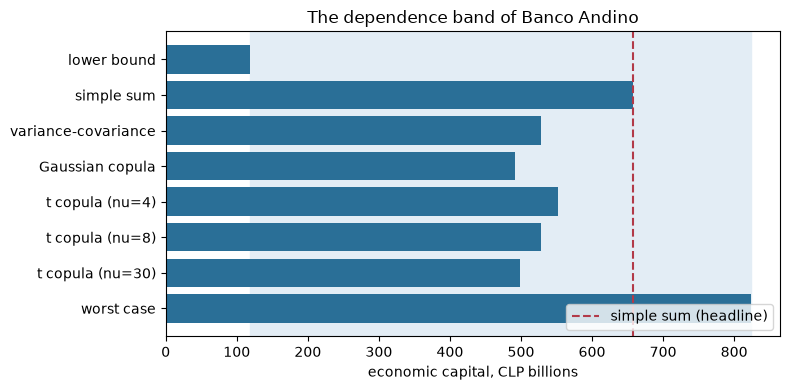

lower bound               118,509  0.1801 information-not-capital
simple sum                658,046  1.0000 headline-capital
variance-covariance       528,106  0.8025 information-not-capital
Gaussian copula           491,999  0.7477 information-not-capital
t copula                  552,369  0.8394 information-not-capital
t copula                  528,318  0.8029 information-not-capital
t copula                  499,133  0.7585 information-not-capital
worst case                823,347  1.2512 information-not-capital


In [7]:
# Run the whole band on the rebuilt marginals with the pipeline's settings and draw it with its bracket
band = rv_band.dependence_band(ppfs, ec, el, R, NU_SET, level=LEVEL, horizon_years=1, n_draws=1_000_000, seed=42,
                               chunk_size=100_000, bounds_n=100_000, bounds_epsilon=1e-3,
                               ec_consistency_tolerance=0.01)
rows = {(r.method, r.nu): r for r in band.rows}
labels = [NAMES[r.method] + (f" (nu={r.nu:g})" if r.nu else "") for r in band.rows]
values = [r.capital / 1e3 for r in band.rows]
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(rows[("lower-bound", None)].capital / 1e3, rows[("worst-case", None)].capital / 1e3, color="#e3edf5")
ax.barh(labels[::-1], values[::-1], color="#2a6f97")
ax.axvline(band.headline / 1e3, color="#b23a48", linestyle="--", label="simple sum (headline)")
ax.set_xlabel("economic capital, CLP billions")
ax.set_title("The dependence band of Banco Andino")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
for r in band.rows:
    print(f"{NAMES[r.method]:22s} {r.capital:10,.0f} {r.diversification_factor:7.4f} {r.status}")

Every row of the band sits inside the shaded bracket, from the lower bound at CLP 118,509 million to the worst case at
823,347 million, and the dashed headline is neither its top nor its bottom. The simple sum (658,046) and the square-root
row (528,106) use only the committed capitals, so they do not change from the closed forms of notebook 01; the two bounds
come from the rebuilt marginals and land on the committed ones within 0.01 percent; the copula rows are those of notebook 02.
The statuses printed beside the numbers matter: only the simple sum is `headline-capital`, every other row is
`information-not-capital`, so a diversified figure cannot be mistaken for the capital of the case.

### Step 5: the structural rule of the band

Whatever the marginals, the lower bound is the best possible VaR of the sum over every dependence structure and the worst case
is the worst possible one, so **every other row of the band lies between them**. The engine's `worst_case_bracket` test
checks it: red when any row is outside the bracket, green otherwise. The next cell runs it on this notebook's band and on a
copy of it in which the Gaussian row has been doubled on purpose, to see the test refuse.

In [8]:
# Run the bracket test on this notebook's band and on a band with the Gaussian row doubled out of the bracket
capital = {key: r.capital for key, r in rows.items()}
inner = [v for (method, nu), v in capital.items() if method not in ("lower-bound", "worst-case")]
lower, worst = capital[("lower-bound", None)], capital[("worst-case", None)]
pushed = [2 * v if v == capital[("gaussian-copula", None)] else v for v in inner]
for label, between in (("this notebook's band", inner), ("a row pushed out", pushed)):
    result = agg_tests.worst_case_bracket(lower, between, worst)
    print(f"{label:28s} {"light"} {LIGHT[result.light.value]:6s} {"rows outside"} {result.extras['rows_outside']}")

this notebook's band         light green  rows outside 0
a row pushed out             light red    rows outside 1


### Step 6: what the correlation stress moves

The case reruns the band with the market-credit correlation raised from 0.5 to 0.8, the upper end of the published ranges (dossier 05, G.5). The three rows that do not depend on the matrix cannot move; the three kinds that do, will. The engine's `correlation_stress` test reads the change of the Gaussian row against an amber gate.

The next cell recomputes the square-root row from the stressed matrix with `variance_covariance`, runs the engine's
`correlation_stress` test on the two Gaussian rows and draws the committed band under the base and the stressed matrix.

stressed pair market credit 0.8
square-root row, stressed matrix 568520.5
Gaussian change and amber gate 0.1211 0.1


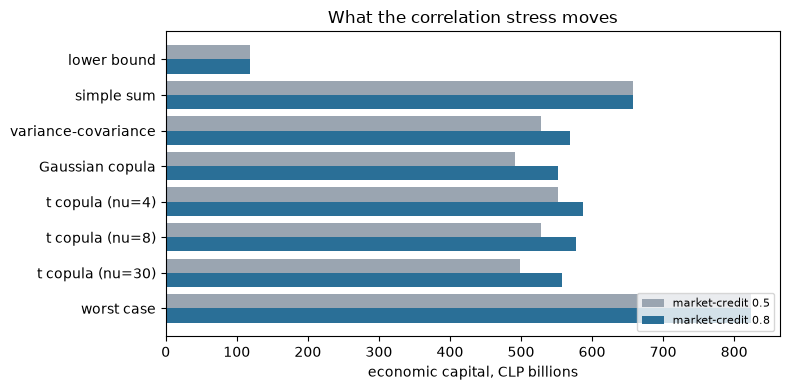

{'lower bound None': 0.0, 'simple sum None': 0.0, 'variance-covariance None': 0.077, 'Gaussian copula None': 0.121, 't copula 4.0': 0.064, 't copula 8.0': 0.092, 't copula 30.0': 0.116, 'worst case None': 0.0}
Gaussian row, percent 12.1


In [9]:
# Recompute the square-root row of the stressed matrix, run the stress test and draw both bands
R_stress = np.array(stress["aggregation"]["correlation"]["matrix"])
print("stressed pair", stress["pair"]["a"], stress["pair"]["b"], stress["pair"]["value"])
print("square-root row, stressed matrix", round(simple.variance_covariance(ec, R_stress), 1))
keys = list(committed)
gaussian = ("gaussian-copula", None)
test = agg_tests.correlation_stress(committed[gaussian]["capital_clp_m"], stressed[gaussian]["capital_clp_m"])
print("Gaussian change and amber gate", round(test.statistic, 4), test.extras["thresholds"]["amber"])
y = np.arange(len(keys))[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
base_bn = [committed[k]["capital_clp_m"] / 1e3 for k in keys]
stress_bn = [stressed[k]["capital_clp_m"] / 1e3 for k in keys]
ax.barh(y + 0.2, base_bn, height=0.4, color="#9aa5b1", label="market-credit 0.5")
ax.barh(y - 0.2, stress_bn, height=0.4, color="#2a6f97", label="market-credit 0.8")
ax.set_yticks(y)
ax.set_yticklabels([NAMES[k[0]] + (f" (nu={k[1]:g})" if k[1] else "") for k in keys])
ax.set_xlabel("economic capital, CLP billions")
ax.set_title("What the correlation stress moves")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
change = {k: stressed[k]["capital_clp_m"] / committed[k]["capital_clp_m"] - 1 for k in keys}
print({f"{NAMES[k[0]]} {k[1]}": round(v, 3) for k, v in change.items()})
print("Gaussian row, percent", round(change[gaussian] * 100, 1))

The three rows that do not depend on the matrix, the lower bound, the simple sum and the worst case, are identical in both
bands, and every other row moves right. Raising the market-credit correlation from 0.5 to 0.8, the top of the published
ranges, lifts the square-root row 7.7 percent to 568,521 and the Gaussian row 12.1 percent, and the engine's test reads the
Gaussian change, 0.1211, against its gate of 0.1 and turns amber. The t rows rise 6.4, 9.2 and 11.6 percent for four, eight
and thirty degrees of freedom. Even the stressed rows stay inside the bracket and below the worst case, which is the point
of having a bracket: it is independent of the matrix that a stress changes.

## Results

**Answer:** no, the simple sum is not the most capital the four risks could need. Over every possible dependence the worst
VaR of the sum asks for CLP 823,347 million, 1.25 times the simple sum of 658,046 million, and the best one only 118,509
million; every diversified row of the band, from the square-root rule at 528,106 million to the t copula with four degrees
of freedom at 552,369 million, lies between those two numbers and `worst_case_bracket` says so, turning red when the Gaussian
row is doubled out. The published example shows how far dependence can go: eight Pareto(2) risks have a comonotonic VaR of
72.0 and a worst VaR of 141.66, a factor of 1.968. A correlation stress of the market-credit pair to 0.8 moves the Gaussian
row by 12.1 percent and leaves both bounds and the simple sum where they were.

What this notebook does not show: the million-draw samples behind the committed rows are not committed, so the marginals come
from a grid of 1,961 points and the rows agree to 0.01 percent and not to the digit; and a worst case computed on marginals is
exact only as far as the marginals are right in their upper tail, here to the grid's reach of 4.8e-7 from the end.

## Summary

- The comonotonic VaR is the VaR of perfectly dependent risks and is not the worst case, because a VaR is not subadditive; the rearrangement algorithm gives the sharp best and worst VaR for known marginals and any dependence.
- The algorithm only permutes values inside each column and aims at equal row sums, which spreads the extremes so that every scenario is bad.
- The band shows, over the same marginals, horizon and level, the lower bound, the simple sum (the headline), the square-root rule, the Gaussian copula, a t copula per degree of freedom and the worst case, each labelled headline or information.
- The bounds and the simple sum do not depend on the correlation matrix; the other rows do, and the matrix is a convention.
- Every row lies inside the bracket, which `worst_case_bracket` checks and turns red when it fails.

**What to try next.** Change `bounds_n` in step 4 to 10,000 and see how much the worst case moves; then continue with notebook 04, which turns macro scenarios into the loss rates that feed the credit marginal.

## References

- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Embrechts, P., McNeil, A. and Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, in Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- This repository: `docs/contracts/engine/aggregation-api.md` (the band, the bounds and the validation tests).